# Name: Vrushabh Pravinbhai Bodarya

# Student_ID: REDACTED

# HW_3 --> Que 6.

# KNN from Scratch vs. sklearn on Iris

In [3]:
# we import essentials calmly so the rest flows
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.neighbors import KNeighborsClassifier
from time import perf_counter
from collections import Counter
np.random.seed(42)  # gentle reproducibility

## Our KNN Classifier (from scratch)

In [4]:

# craft a tiny, cozy KNN by hand
class MyKNN:
    def __init__(self, n_neighbors=5, weights='uniform'):
        assert isinstance(n_neighbors, int) and n_neighbors >= 1, "n_neighbors must be an integer ≥ 1"
        assert weights in ('uniform', 'distance'), "weights must be 'uniform' or 'distance'"
        self.n_neighbors = n_neighbors
        self.weights = weights
        self._X = None
        self._y = None

    def fit(self, X, y):
        # we simply remember the training set like a good friend
        self._X = np.asarray(X, dtype=float)
        self._y = np.asarray(y)
        return self

    @staticmethod
    def _euclidean_distances(A, B):
        # we use a vectorized distance for speed and serenity
        # A shape: (m, d), B shape: (n, d) -> returns (m, n)
        A2 = np.sum(A**2, axis=1)[:, None]
        B2 = np.sum(B**2, axis=1)[None, :]
        AB = A @ B.T
        d2 = A2 + B2 - 2*AB
        # numerical jitter for safety
        np.maximum(d2, 0, out=d2)
        return np.sqrt(d2)

    def predict(self, X):
        # we compute distances and then softly vote
        X = np.asarray(X, dtype=float)
        dists = self._euclidean_distances(X, self._X)  # shape (m, n_train)
        m = X.shape[0]
        preds = np.empty(m, dtype=self._y.dtype)
        eps = 1e-9  # kindness to prevent division by zero

        for i in range(m):
            # we peek at the nearest neighbors with gentle curiosity
            idx = np.argpartition(dists[i], self.n_neighbors)[:self.n_neighbors]
            nn_labels = self._y[idx]
            if self.weights == 'uniform':
                # simple majority vote when everyone's voice is equal
                most_common = Counter(nn_labels).most_common()
                # break ties deterministically by smallest label
                max_count = most_common[0][1]
                candidates = sorted([lab for lab, c in most_common if c == max_count])
                preds[i] = candidates[0]
            else:
                # distance-weighted vote (closer neighbors speak a bit louder)
                nn_d = dists[i, idx]
                w = 1.0 / (nn_d + eps)
                # accumulate weights per class
                class_weights = {}
                for lab, weight in zip(nn_labels, w):
                    class_weights[lab] = class_weights.get(lab, 0.0) + weight
                # choose the label with maximum total weight (break ties by smallest label)
                max_w = max(class_weights.values())
                candidates = sorted([lab for lab, total in class_weights.items() if np.isclose(total, max_w)])
                preds[i] = candidates[0]
        return preds


## Load Iris and Split

In [5]:

# I fetch the classic iris dataset gently
iris = datasets.load_iris()
X, y = iris.data, iris.target

# a calm train/test split to evaluate fairly
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)
X_train.shape, X_test.shape

((105, 4), (45, 4))

## Helper: evaluate a classifier

In [6]:

# we define a tiny helper to measure how everyone performs
def evaluate_model(clf, name):
    t0 = perf_counter()
    clf.fit(X_train, y_train)
    fit_time = perf_counter() - t0

    t1 = perf_counter()
    y_pred = clf.predict(X_test)
    pred_time = perf_counter() - t1

    acc = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    print(f"\n{name}")
    print(f"Accuracy: {acc:.4f}")
    print(f"Fit time: {fit_time*1000:.2f} ms")
    print(f"Predict time: {pred_time*1000:.2f} ms")
    print("Confusion Matrix:\n", cm)
    print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=iris.target_names))
    return acc, fit_time, pred_time, cm


## Compare: MyKNN vs. sklearn KNeighborsClassifier

In [7]:

# we try a friendly setting for both models
my_knn = MyKNN(n_neighbors=5, weights='uniform')
sk_knn = KNeighborsClassifier(n_neighbors=5, weights='uniform')

acc_my, ft_my, pt_my, cm_my = evaluate_model(my_knn, "MyKNN (k=5, uniform)")
acc_sk, ft_sk, pt_sk, cm_sk = evaluate_model(sk_knn, "sklearn KNN (k=5, uniform)")

# insights: both should be quite similar on Iris; sklearn is optimized in C for speed
print("\nInsight: On Iris, accuracies tend to match; sklearn is usually faster due to optimized internals.")



MyKNN (k=5, uniform)
Accuracy: 0.9778
Fit time: 0.01 ms
Predict time: 8.96 ms
Confusion Matrix:
 [[15  0  0]
 [ 0 15  0]
 [ 0  1 14]]

Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.94      1.00      0.97        15
   virginica       1.00      0.93      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45


sklearn KNN (k=5, uniform)
Accuracy: 0.9778
Fit time: 2.19 ms
Predict time: 2.02 ms
Confusion Matrix:
 [[15  0  0]
 [ 0 15  0]
 [ 0  1 14]]

Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.94      1.00      0.97        15
   virginica       1.00      0.93      0.97        15

    accuracy                           0.98        45
   macro avg       0.

### Distance-Weighted Variant

In [8]:
# we also explore distance weighting with the same k
my_knn_dist = MyKNN(n_neighbors=5, weights='distance')
sk_knn_dist = KNeighborsClassifier(n_neighbors=5, weights='distance')

acc_my_d, ft_my_d, pt_my_d, cm_my_d = evaluate_model(my_knn_dist, "MyKNN (k=5, distance)")
acc_sk_d, ft_sk_d, pt_sk_d, cm_sk_d = evaluate_model(sk_knn_dist, "sklearn KNN (k=5, distance)")

# tiny reflection for humans: distance weights can help when classes overlap softly
print("\nHuman note: distance weighting often helps when nearby points matter more than a distant majority.")



MyKNN (k=5, distance)
Accuracy: 0.9778
Fit time: 0.01 ms
Predict time: 5.70 ms
Confusion Matrix:
 [[15  0  0]
 [ 0 15  0]
 [ 0  1 14]]

Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.94      1.00      0.97        15
   virginica       1.00      0.93      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45


sklearn KNN (k=5, distance)
Accuracy: 0.9778
Fit time: 0.80 ms
Predict time: 1.41 ms
Confusion Matrix:
 [[15  0  0]
 [ 0 15  0]
 [ 0  1 14]]

Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.94      1.00      0.97        15
   virginica       1.00      0.93      0.97        15

    accuracy                           0.98        45
   macro avg       

## Cross-Validation (5-fold)

In [9]:

# we peek at stability across folds kindly
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def cv_score_for_myknn(k=5, weights='uniform'):
    # wrap MyKNN for cross_val_score via manual loop
    scores = []
    for train_idx, test_idx in cv.split(X, y):
        clf = MyKNN(n_neighbors=k, weights=weights).fit(X[train_idx], y[train_idx])
        y_hat = clf.predict(X[test_idx])
        scores.append(accuracy_score(y[test_idx], y_hat))
    return np.array(scores)

scores_my = cv_score_for_myknn(k=5, weights='uniform')
scores_sk = cross_val_score(KNeighborsClassifier(n_neighbors=5, weights='uniform'), X, y, cv=cv)

print("MyKNN CV Accuracy:   {:.4f} ± {:.4f}".format(scores_my.mean(), scores_my.std()))
print("sklearn CV Accuracy: {:.4f} ± {:.4f}".format(scores_sk.mean(), scores_sk.std()))

# a soft takeaway
print("\nInsight: With careful implementation, from-scratch KNN can match sklearn's accuracy on small datasets.")

MyKNN CV Accuracy:   0.9733 ± 0.0249
sklearn CV Accuracy: 0.9667 ± 0.0298

Insight: With careful implementation, from-scratch KNN can match sklearn's accuracy on small datasets.


## (Optional) Quick 2D decision boundary sketch

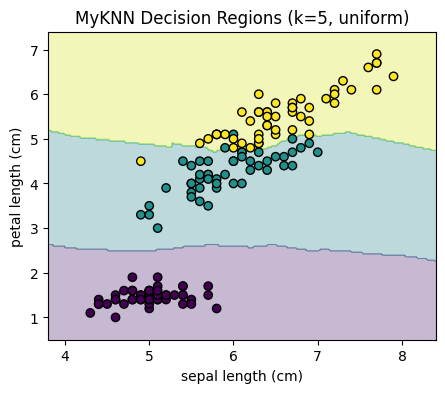

In [10]:

# we draw a simple boundary using only two features for a friendly visual
feat_idx = (0, 2)  # sepal length & petal length for a quick vibe
X2 = X[:, feat_idx]
x_min, x_max = X2[:,0].min()-0.5, X2[:,0].max()+0.5
y_min, y_max = X2[:,1].min()-0.5, X2[:,1].max()+0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))

clf2 = MyKNN(n_neighbors=5, weights='uniform').fit(X2, y)
grid = np.c_[xx.ravel(), yy.ravel()]
Z = clf2.predict(grid).reshape(xx.shape)

plt.figure(figsize=(5,4))
plt.contourf(xx, yy, Z, alpha=0.3)
plt.scatter(X2[:,0], X2[:,1], c=y, edgecolor='k')
plt.xlabel(datasets.load_iris().feature_names[feat_idx[0]])
plt.ylabel(datasets.load_iris().feature_names[feat_idx[1]])
plt.title("MyKNN Decision Regions (k=5, uniform)")
plt.show()
